# **Laboratory III**

**Students:**
**Mălina-Teodora Dumitrescu, 7729845**
**Niloofar Amiri, 7513798**

Github Repository: https://github.com/MalinaDumitrescu/advanced-medical-informatics/blob/main/labor_3.ipynb

## **Problem 1**

![Screenshot 2026-11-11 142635.png](../pictures/Screenshot%202026-11-11%20142635.png)

a. **A Bayesian network** is a model that uses probabilities to describe relationships between different variables. It is represented as a directed acyclic graph (DAG), where nodes represent variables and arrows show how they depend on each other. These relationships are described using conditional probabilities.

**In a CDSS**, it can be used to estimate how likely a patient is to have a certain disease based on their symptoms, risk factors and test results. This helps doctors make decisions even when they don't have all the information.

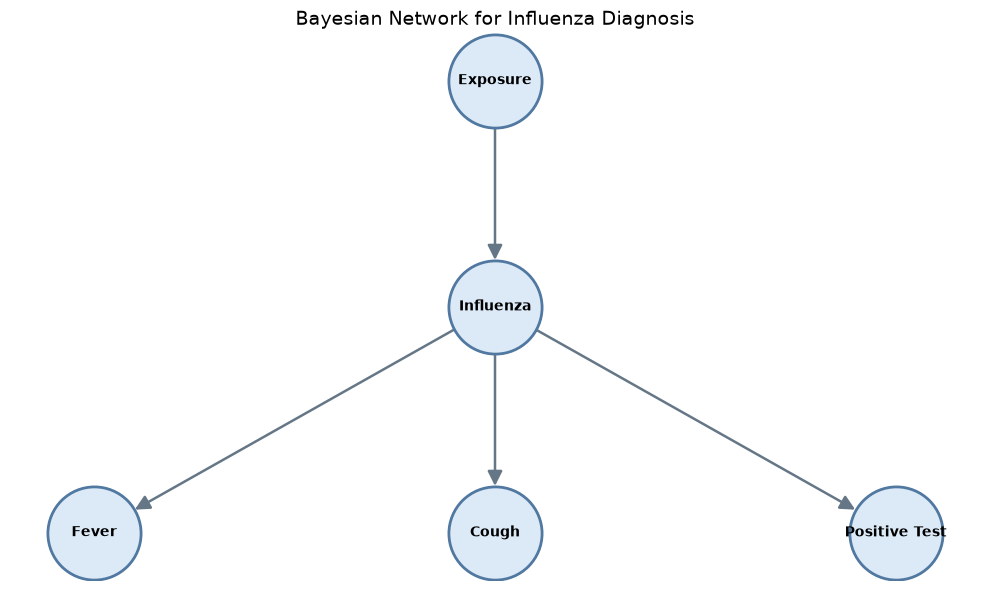

In [4]:
import networkx as nx # it builds the graph, the nodes and the way they are connected
import matplotlib.pyplot as plt # we use this one for plotting the graph, choosing the colors, the size of the nodes and the arrows, etc.
G = nx.DiGraph() # we create a directed graph as an object of the class and save it into our variable G, that at init stage is just an empty graph

G.add_edges_from([
    ("Exposure", "Influenza"),
    ("Influenza", "Fever"),
    ("Influenza", "Cough"),
    ("Influenza", "Positive Test")
]) # we add the nodes and edges

pos = {
    "Exposure": (0, 2),
    "Influenza": (0, 1),
    "Fever": (-2, 0),
    "Cough": (0, 0),
    "Positive Test": (2, 0)
} # we use python dict to define the position of each node in the graph

# we create a figure with a specific size to plot the graph in inch
plt.figure(figsize=(10, 6))

# we draw the nodes
nx.draw_networkx_nodes(
    G, pos,
    node_shape="o",
    node_size=4500, # it's not a diameter in inches, but a size in points^2, so the diameter is sqrt(4500) = 67.08 points
    node_color="#DCEAF7",
    edgecolors="#5078A0",
    linewidths=2
)
# we draw the edges
nx.draw_networkx_edges(
    G, pos,
    arrows=True, # activates the use of arrows
    arrowsize=22, # it chooses the size of the arrowhead
    arrowstyle="-|>", # it chooses the shape of the arrowhead
    node_size=4500, # for the arrows to stop correctly before entering the node itself
    width=1.8,
    edge_color="#657786"
)

nx.draw_networkx_labels(
    G, pos,
    font_size=10,
    font_weight="bold"
)

plt.title("Bayesian Network for Influenza Diagnosis", fontsize=14)
plt.axis("off")
plt.tight_layout()
plt.show()

b. **BICS - Brigham Integrated Computing System** was developed at Brigham and Women's Hospital to manage clinical, administrative and financial information. One of its main goals was to support doctors in their daily work and improve patient safety, especially by reducing medication errors through computerized ordering and decision support.

c. **LMR - Longitudinal Medical Record** is an electronic medical record system that stores patient information over time, including diagnoses, medications, allergies, test results and medical notes. Its main purpose is to give healthcare professionals access to a patient's medical history in one place, making it easier to monitor their health and make informed treatment decisions.

d. **A CDSS could warn a doctor if they try to prescribe isotretinoin to a pregnant patient**, since this medication can cause serious birth defects. The system could recognize the risk from the patient's medical record and display a warning before the prescription is completed.

e. **ADE - Adverse Drug Event** refers to any harm caused by the use of a medication. This can happen because of a medication error, but also when the medication is used correctly.

f. **BICS initially reduced serious ADEs** by 55%. After further improvements, the reduction reached 88%, while the overall medication error rate decreased by 81%. (LECTURE 6, SLIDE 28)

G. According to Epic's official website: "More than 325 million patients have an electronic health record in Epic". (https://www.epic.com/about/)

## **Problem 2**

![Screenshot 2026-11-11 142847.png](../pictures/Screenshot%202026-11-11%20142847.png)

**Association Analysis - PLINK** -
https://www.cog-genomics.org/plink/1.9/assoc

**Standard data input - PLINK**
https://www.cog-genomics.org/plink2/input?utm_source=chatgpt.com

a. For this part of the exercise we only need to run the command **plink --bfile GWAS_data --assoc --out GWAS_results** in the cmd.

plink => runs PLINK from the current folder
--bfile GWAS_data => specifies the input fileset, so it loads the .bed, .bim and .fam files
--assoc => runs the basic association test for each eligible SNP in the dataset
--out GWAS_results => sets the output filename prefix

Therefore, after running the command PLINK will read the dataset, identify rhe available phenotypes and variants, and calculate the association statistics.

b.

![Screenshot (705).png](../pictures/Screenshot%20%28705%29.png)

![Screenshot 2026-11-11 153025.png](../pictures/Screenshot%202026-11-11%20153025.png)

The histogram shows the distribution of p-values obtained from the association analysis. Most p-values are distributed approximately uniformly between 0 and 1, with no strong overall concentration in a particular interval.

c. For this part of the exercise we will start by running the plink.exe --bfile GWAS_data --assoc **--adjust** --out GWAS_corrected command in the cmd. This runs the same association analysis as in a. but --adjust additionally calculates corrected p-values.

Now we open GWAS_corrected.assoc.adjusted in Excel.

We used Excel to identify the associations that passed the Bonferroni correction.

First, we counted the valid p-values using:

`=COUNT(I2:I100101)`

This gave **100,002 tests**. we then calculated the Bonferroni significance threshold:

`=0.05/100002`

The resulting threshold was approximately **5.0 × 10⁻⁷**.

Finally, we opened the PLINK-adjusted results in Excel and filtered the `BONF` column to keep only values ≤ 0.05. To count the significant associations, I used:

`=COUNTIF(E2:E100101;"<=0,05")`

The remaining rows represent the SNPs that passed the Bonferroni correction.
\[
p_{\text{threshold}} = \frac{0.05}{100002} \approx 5.0 \times 10^{-7}
\]

We selected the SNPs with Bonferroni-adjusted p-values of 0.05 or less.

![Screenshot (706).png](../pictures/Screenshot%20%28706%29.png)

Number of valid p-values: 100050


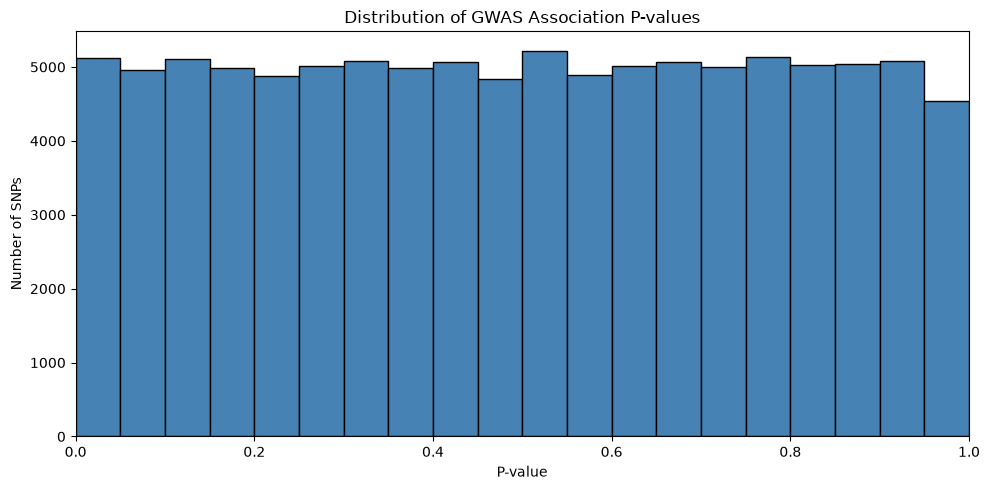

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read the association results
df = pd.read_csv("labor_3/PLINK/GWAS_results.assoc", sep=r"\s+")
# Extract valid p-values
p_values = pd.to_numeric(df["P"], errors="coerce").dropna()
p_values = p_values[(p_values >= 0) & (p_values <= 1)]

print("Number of valid p-values:", len(p_values))

# Plot the histogram
plt.figure(figsize=(10, 5))

plt.hist(
    p_values,
    bins=np.linspace(0, 1, 21),
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribution of GWAS Association P-values")
plt.xlabel("P-value")
plt.ylabel("Number of SNPs")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

In [23]:
m = len(p_values)
threshold = 0.05 / m

print("Number of tests:", m)
print(f"Bonferroni threshold: {threshold:.10e}")

# Find significant associations
df["P"] = pd.to_numeric(df["P"], errors="coerce")

significant = df[
    df["P"].notna() & (df["P"] <= threshold)
].copy()

significant["BONF"] = np.minimum(
    significant["P"] * m, 1.0
)

result = significant[["CHR", "SNP", "BP", "P", "BONF"]]

print("Number of significant SNPs:", len(result))
display(result)

Number of tests: 100050
Bonferroni threshold: 4.9975012494e-07
Number of significant SNPs: 80


,CHR,SNP,BP,P,BONF
100002,1,disease_2,100003,9.695000e-26,9.699847e-21
100003,1,disease_3,100004,3.111000e-18,3.112555e-13
100004,1,disease_4,100005,2.477000e-26,2.478238e-21
100005,1,disease_5,100006,5.567000e-23,5.569783e-18
100006,1,disease_6,100007,1.898000e-19,1.898949e-14
...,...,...,...,...,...
100095,1,disease_95,100096,2.502000e-22,2.503251e-17
100096,1,disease_96,100097,4.435000e-22,4.437218e-17
100097,1,disease_97,100098,4.171000e-10,4.173086e-05
100098,1,disease_98,100099,7.682000e-20,7.685841e-15


In [25]:
from pathlib import Path

output_folder = Path("labor_3")
output_folder.mkdir(exist_ok=True)

result.to_csv(
    output_folder / "Bonferroni_significant_SNPs.csv",
    index=False
)

result.to_excel(
    output_folder / "Bonferroni_significant_SNPs.xlsx",
    index=False
)